# Домашнее задание 1

## Запуск

Установите зависимости командой 
```
pip install -r requirements.txt
``` 
и запустите ячейки сверху вниз. Ячейка загрузки автоматически скачивает файлы с Kaggle.

## 1. Датасет и загрузка данных

Используем Amazon Review Data 2018 — Video Games 5-core. Это отзывы пользователей о товарах категории Video Games

Источники данных:

- [Датасет отзывов Video Games](https://www.kaggle.com/datasets/idrimadrid/games-review-amazon)
- [Датасет метаданных Video Games](https://www.kaggle.com/datasets/khaledsayed111/meta-video-games)

### Что является взаимодействием

Одна строка файла отзывов — это взаимодействие пользователя с товаром: пользователь (reviewerID) оставил отзыв о товаре (asin), поставив оценку (overall) в момент времени (unixReviewTime)

| Поле | Смысл | Использование |
|---|---|---|
| reviewerID | идентификатор пользователя | user ID |
| asin | идентификатор товара | item ID |
| overall | оценка товара от 1 до 5 | explicit feedback и целевой сигнал ALS |
| unixReviewTime | время публикации отзыва в Unix time | временное разбиение и временные компоненты |
| reviewTime | дата отзыва в строковом формате | проверка timestamp |

В исходном файле метаданных доступны поля title, description, brand, category, categories и price. Поле category приводится к categories

In [1]:
from __future__ import annotations

import gzip
import json
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

/Users/dfstolyar/Documents/ysda/2year/deep_vision_and_graphics/homework01/.venv-mps/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import shutil
import zipfile

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

REVIEWS_URL = "https://www.kaggle.com/api/v1/datasets/download/idrimadrid/games-review-amazon"
METADATA_URL = "https://www.kaggle.com/api/v1/datasets/download/khaledsayed111/meta-video-games"

REVIEWS_PATH = DATA_DIR / "Video_Games_5.json.gz"
METADATA_PATH = DATA_DIR / "meta_Video_Games.json.gz"

if not REVIEWS_PATH.exists():
    reviews_zip = DATA_DIR / "games-review-amazon.zip"
    urllib.request.urlretrieve(REVIEWS_URL, reviews_zip)
    with zipfile.ZipFile(reviews_zip) as archive:
        with archive.open("Video_Games_5.json") as source:
            with gzip.open(REVIEWS_PATH, "wb") as target:
                shutil.copyfileobj(source, target)
    reviews_zip.unlink()

if not METADATA_PATH.exists():
    metadata_zip = DATA_DIR / "meta-video-games.zip"
    urllib.request.urlretrieve(METADATA_URL, metadata_zip)
    with zipfile.ZipFile(metadata_zip) as archive:
        with archive.open("meta_Video_Games.json") as source:
            with gzip.open(METADATA_PATH, "wb") as target:
                shutil.copyfileobj(source, target)
    metadata_zip.unlink()

In [3]:
def load_jsonl_gz(path: Path, columns: list[str], description: str) -> pd.DataFrame:
    rows = []
    with gzip.open(path, mode="rt", encoding="utf-8") as file:
        for line in tqdm(file, desc=description):
            record = json.loads(line)
            rows.append({column: record.get(column) for column in columns})
    return pd.DataFrame.from_records(rows, columns=columns)

review_columns = [
    "reviewerID",
    "asin",
    "overall",
    "unixReviewTime",
    "reviewTime",
]
metadata_columns = [
    "asin",
    "title",
    "description",
    "brand",
    "category",
    "categories",
    "price",
]

reviews_raw = load_jsonl_gz(REVIEWS_PATH, review_columns, "Loading reviews")
items_raw = load_jsonl_gz(METADATA_PATH, metadata_columns, "Loading item metadata")
items_raw["categories"] = items_raw["categories"].fillna(items_raw["category"])
items_raw = items_raw.drop(columns=["category"])

reviews_raw["timestamp"] = pd.to_datetime(
    reviews_raw["unixReviewTime"], unit="s", utc=True
)

reviews_raw.head()

Loading reviews: 0it [00:00, ?it/s]

Loading reviews: 497577it [00:03, 153424.99it/s]
Loading item metadata: 84819it [00:01, 59499.09it/s]


,reviewerID,asin,overall,unixReviewTime,reviewTime,timestamp
0,A1HP7NVNPFMA4N,0700026657,5.0,1445040000,"10 17, 2015",2015-10-17 00:00:00+00:00
1,A1JGAP0185YJI6,0700026657,4.0,1437955200,"07 27, 2015",2015-07-27 00:00:00+00:00
2,A1YJWEXHQBWK2B,0700026657,3.0,1424649600,"02 23, 2015",2015-02-23 00:00:00+00:00
3,A2204E1TH211HT,0700026657,2.0,1424390400,"02 20, 2015",2015-02-20 00:00:00+00:00
4,A2RF5B5H74JLPE,0700026657,5.0,1419465600,"12 25, 2014",2014-12-25 00:00:00+00:00


### Что рекомендуем и что считаем релевантным

Рекомендуемый объект — товар из категории Video Games. Для каждого пользователя строим персональный список из 10 товаров, которые не встречались в его истории

Для оценки рекомендаций товар считается релевантным, если пользователь поставил ему в отложенной части данных оценку overall >= 4. Это правило одинаково для всех моделей, а обучаться они могут на оценках от 1 до 5

Поскольку в Amazon нет явных показов нерелевантных товаров, отсутствие отзыва не трактуем как отрицательную оценку

In [4]:
summary = pd.Series({
    "review rows loaded": len(reviews_raw),
    "unique users": reviews_raw["reviewerID"].nunique(),
    "unique interacted items": reviews_raw["asin"].nunique(),
    "metadata rows loaded": len(items_raw),
    "unique metadata items": items_raw["asin"].nunique(),
    "reviews with matching metadata, %": (
        reviews_raw["asin"].isin(items_raw["asin"]).mean() * 100
    ),
    "minimum reviews per user in source": reviews_raw.groupby("reviewerID").size().min(),
    "minimum reviews per item in source": reviews_raw.groupby("asin").size().min(),
    "first interaction": reviews_raw["timestamp"].min(),
    "last interaction": reviews_raw["timestamp"].max(),
}).to_frame("value")

summary

,value
review rows loaded,497577
unique users,55223
unique interacted items,17408
metadata rows loaded,84819
unique metadata items,71911
"reviews with matching metadata, %",99.746371
minimum reviews per user in source,4
minimum reviews per item in source,1
first interaction,1999-10-14 00:00:00+00:00
last interaction,2018-10-02 00:00:00+00:00


In [5]:
missingness = pd.DataFrame({
    "reviews_missing": reviews_raw.isna().sum(),
    "reviews_missing_%": reviews_raw.isna().mean().mul(100).round(2),
})

metadata_missingness = pd.DataFrame({
    "metadata_missing": items_raw.isna().sum(),
    "metadata_missing_%": items_raw.isna().mean().mul(100).round(2),
})

display(missingness)
display(metadata_missingness)
display(items_raw.head(3))

,reviews_missing,reviews_missing_%
reviewerID,0,0.0
asin,0,0.0
overall,0,0.0
unixReviewTime,0,0.0
reviewTime,0,0.0
timestamp,0,0.0


,metadata_missing,metadata_missing_%
asin,0,0.0
title,0,0.0
description,0,0.0
brand,0,0.0
categories,0,0.0
price,0,0.0


,asin,title,description,brand,categories,price
0,0042000742,Reversi Sensory Challenger,[],Fidelity Electronics,"[Video Games, PC, Games]",
1,0078764343,Medal of Honor: Warfighter - Includes Battlefi...,[Brand new sealed!],by\n \n EA Games,"[Video Games, Xbox 360, Games, </span></span><...","\n\t\t\t\t\t\t\t\t\t\t\t\t<span class=""vertica..."
2,0276425316,street fighter 2 II turbo super nintendo snes ...,[],Nintendo,"[Video Games, Retro Gaming & Microconsoles, Su...",$0.72


## 2. Очистка и разведочный анализ данных

Удаляем записи без обязательных полей. Для повторных взаимодействий одной пары user-item оставляем последнее по времени. Для повторных записей метаданных оставляем вариант с наибольшим числом заполненных полей

In [6]:
required_review_columns = [
    "reviewerID",
    "asin",
    "overall",
    "timestamp",
]

reviews_clean = reviews_raw.copy()
reviews_clean["overall"] = pd.to_numeric(
    reviews_clean["overall"], errors="coerce"
)
reviews_clean = reviews_clean.dropna(subset=required_review_columns)

exact_duplicate_rows = int(reviews_clean.duplicated().sum())
repeated_user_item_rows = int(
    reviews_clean.duplicated(subset=["reviewerID", "asin"], keep=False).sum()
)
repeated_user_item_pairs = int(
    reviews_clean.groupby(["reviewerID", "asin"]).size().gt(1).sum()
)

reviews = (
    reviews_clean.sort_values(["reviewerID", "asin", "timestamp", "unixReviewTime"], kind="mergesort")
    .drop_duplicates(subset=["reviewerID", "asin"], keep="last")
    .reset_index(drop=True)
)

items = items_raw.dropna(subset=["asin"]).copy()
items["_filled_fields"] = items.drop(columns=["asin"]).notna().sum(axis=1)
metadata_duplicate_rows = int(items.duplicated(subset=["asin"], keep=False).sum())
items = (
    items.sort_values(["asin", "_filled_fields"], ascending=[True, False], kind="mergesort")
    .drop_duplicates(subset=["asin"], keep="first")
    .drop(columns=["_filled_fields"])
    .reset_index(drop=True)
)

cleaning_report = pd.Series({
    "review rows before cleaning": len(reviews_raw),
    "rows removed due to missing required fields": len(reviews_raw) - len(reviews_clean),
    "exact duplicate review rows": exact_duplicate_rows,
    "rows in repeated user-item pairs": repeated_user_item_rows,
    "repeated user-item pairs": repeated_user_item_pairs,
    "review rows after cleaning": len(reviews),
    "metadata rows after cleaning": len(items),
    "metadata duplicate rows": metadata_duplicate_rows,
}).to_frame("value")

cleaning_report

,value
review rows before cleaning,497577
rows removed due to missing required fields,0
exact duplicate review rows,23718
rows in repeated user-item pairs,48087
repeated user-item pairs,23937
review rows after cleaning,473427
metadata rows after cleaning,71911
metadata duplicate rows,25816


In [7]:
def is_empty_metadata_value(value) -> bool:
    if isinstance(value, (list, tuple)):
        return len(value) == 0
    if isinstance(value, str):
        return not value.strip()
    return bool(pd.isna(value))

metadata_fields = ["title", "description", "brand", "categories", "price"]
metadata_quality = pd.DataFrame(index=metadata_fields)
metadata_quality["empty_values"] = [
    items[field].map(is_empty_metadata_value).sum()
    for field in metadata_fields
]
metadata_quality["empty_values_%"] = (
    metadata_quality["empty_values"] / len(items) * 100
).round(2)

reviewed_item_ids = set(reviews["asin"])
matched_review_rows = reviews["asin"].isin(items["asin"])
matched_item_ids = reviewed_item_ids.intersection(set(items["asin"]))
coverage = pd.Series({
    "reviewed items": len(reviewed_item_ids),
    "reviewed items with metadata": len(matched_item_ids),
    "item metadata coverage, %": len(matched_item_ids) / len(reviewed_item_ids) * 100,
    "reviews with metadata": int(matched_review_rows.sum()),
    "review coverage by metadata, %": matched_review_rows.mean() * 100,
}).to_frame("value")

display(metadata_quality)
display(coverage.round(2))

,empty_values,empty_values_%
title,8,0.01
description,8961,12.46
brand,3617,5.03
categories,2091,2.91
price,22487,31.27


,value
reviewed items,17408.00
reviewed items with metadata,17389.00
"item metadata coverage, %",99.89
reviews with metadata,472743.00
"review coverage by metadata, %",99.86


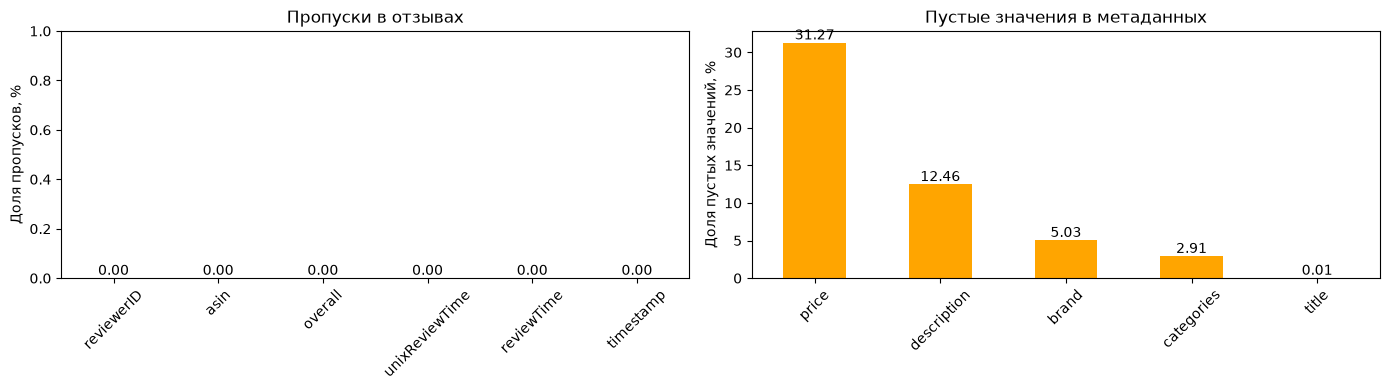

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

review_missing_plot = missingness["reviews_missing_%"].sort_values(ascending=False)
review_missing_plot.plot.bar(ax=axes[0], color="blue")
axes[0].set_title("Пропуски в отзывах")
axes[0].set_ylabel("Доля пропусков, %")
axes[0].set_ylim(0, max(review_missing_plot.max() * 1.2, 1))
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[0].tick_params(axis="x", rotation=45)

metadata_empty_plot = metadata_quality["empty_values_%"].sort_values(ascending=False)
metadata_empty_plot.plot.bar(ax=axes[1], color="orange")
axes[1].set_title("Пустые значения в метаданных")
axes[1].set_ylabel("Доля пустых значений, %")
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

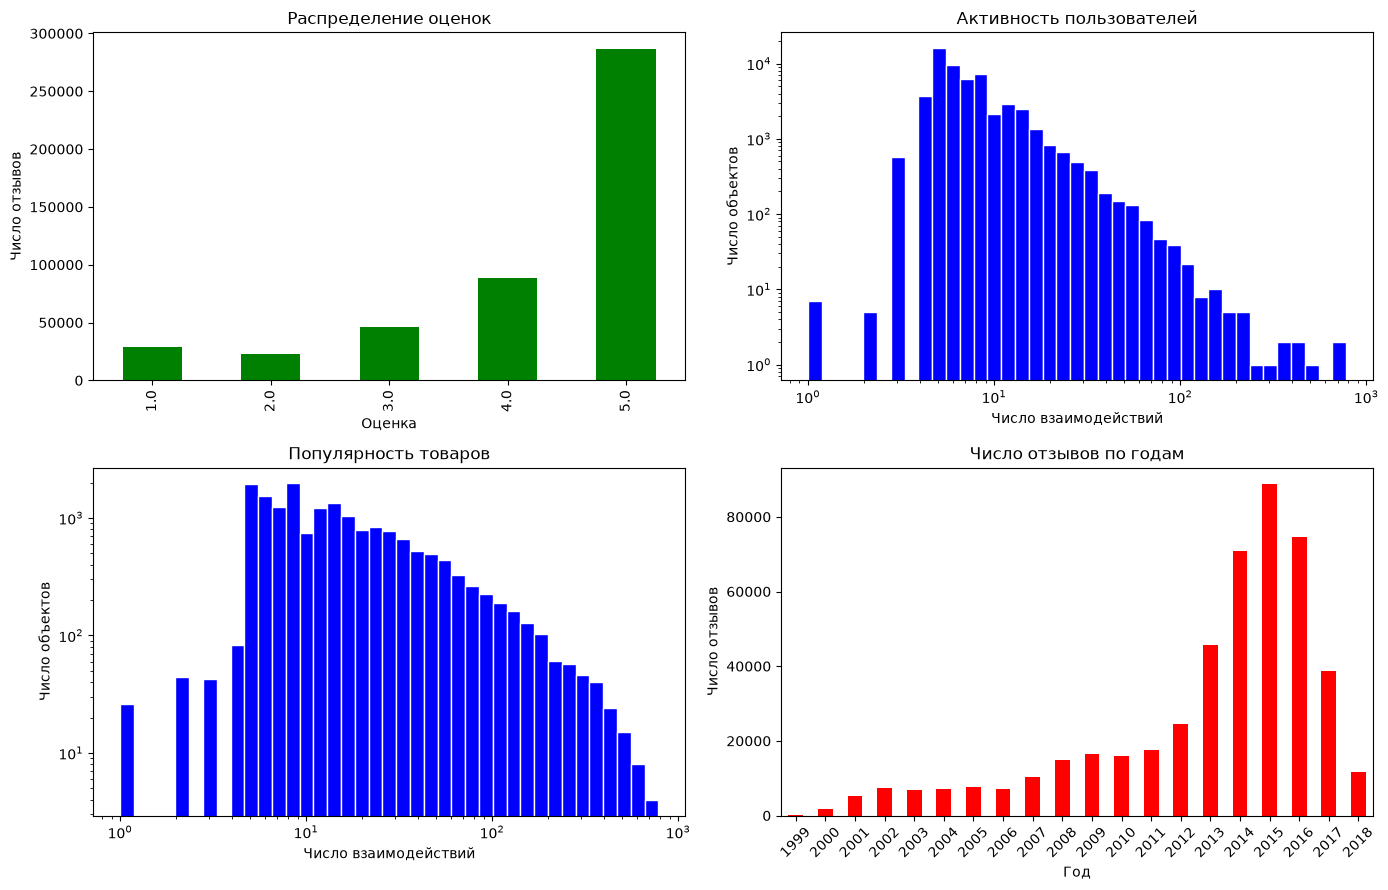

In [9]:
user_activity = reviews.groupby("reviewerID").size()
item_activity = reviews.groupby("asin").size()

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

reviews["overall"].value_counts().sort_index().plot.bar(
    ax=axes[0, 0], color="green"
)
axes[0, 0].set_title("Распределение оценок")
axes[0, 0].set_xlabel("Оценка")
axes[0, 0].set_ylabel("Число отзывов")

for series, axis, title in [
    (user_activity, axes[0, 1], "Активность пользователей"),
    (item_activity, axes[1, 0], "Популярность товаров"),
]:
    bins = np.geomspace(1, max(int(series.max()), 1) + 1, 40)
    axis.hist(series, bins=bins, color="blue", edgecolor="white")
    axis.set_xscale("log")
    axis.set_yscale("log")
    axis.set_title(title)
    axis.set_xlabel("Число взаимодействий")
    axis.set_ylabel("Число объектов")

year_activity = reviews["timestamp"].dt.year.value_counts().sort_index()
year_activity.plot.bar(ax=axes[1, 1], color="red")
axes[1, 1].set_title("Число отзывов по годам")
axes[1, 1].set_xlabel("Год")
axes[1, 1].set_ylabel("Число отзывов")
axes[1, 1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

,value
users,"55,223"
items,"17,408"
interactions,"473,427"
matrix cells,"961,321,984"
"density, %",0.0492
"sparsity, %",99.95


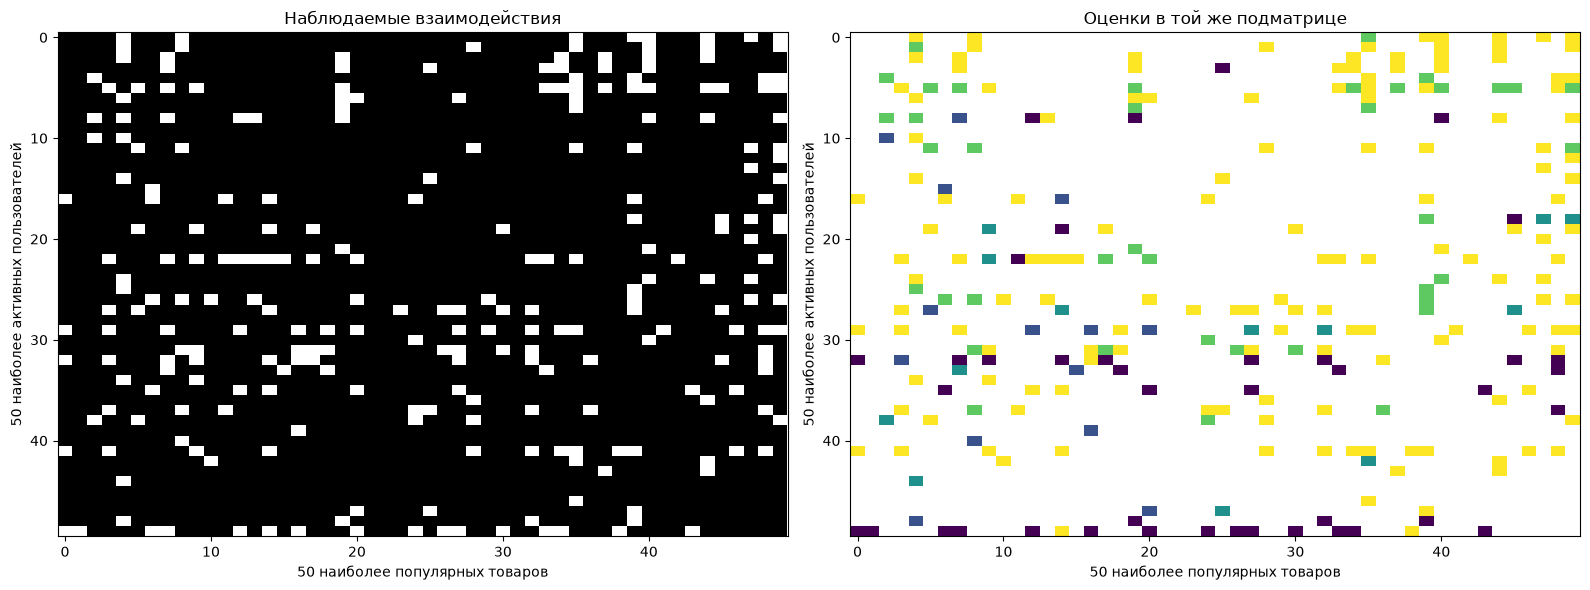

In [10]:
n_users = reviews["reviewerID"].nunique()
n_items = reviews["asin"].nunique()
n_interactions = len(reviews)
density = n_interactions / (n_users * n_items)
sparsity = 1 - density

matrix_stats = pd.Series({
    "users": f"{n_users:,}",
    "items": f"{n_items:,}",
    "interactions": f"{n_interactions:,}",
    "matrix cells": f"{n_users * n_items:,}",
    "density, %": f"{density * 100:.4f}",
    "sparsity, %": f"{sparsity * 100:.2f}",
}).to_frame("value")

display(matrix_stats)

top_users = user_activity.nlargest(50).index
top_items = item_activity.nlargest(50).index
sample_matrix = (
    reviews[reviews["reviewerID"].isin(top_users) & reviews["asin"].isin(top_items)]
    .pivot(index="reviewerID", columns="asin", values="overall")
    .reindex(index=top_users, columns=top_items)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(
    sample_matrix.notna().to_numpy(),
    aspect="auto",
    interpolation="none",
    cmap="gray",
)
axes[0].set_title("Наблюдаемые взаимодействия")
axes[0].set_xlabel("50 наиболее популярных товаров")
axes[0].set_ylabel("50 наиболее активных пользователей")

rating_matrix = np.ma.masked_invalid(sample_matrix.to_numpy(dtype=float))
rating_cmap = plt.get_cmap("viridis").copy()
rating_cmap.set_bad("white")
axes[1].imshow(
    rating_matrix,
    aspect="auto",
    interpolation="none",
    cmap=rating_cmap,
    vmin=1,
    vmax=5,
)
axes[1].set_title("Оценки в той же подматрице")
axes[1].set_xlabel("50 наиболее популярных товаров")
axes[1].set_ylabel("50 наиболее активных пользователей")

plt.tight_layout()
plt.show()

### Выводы по данным

После очистки в данных остается 473 427 взаимодействий 55 223 пользователей с 17 408 товарами. Матрица взаимодействий разрежена на 99.95%, поэтому рекомендации нужно строить по небольшому числу наблюдений для каждой пары user-item

В отзывах нет пропусков в используемых полях. Метаданные покрывают 99.89% товаров с отзывами. Для FM используем brand и categories: это категориальные признаки товара с небольшой долей пустых значений. title и description — текстовые поля, для которых нужна отдельная обработка, а price часто отсутствует.

## 3. Протокол оценки

### Разбиение и данные

Взаимодействия делим по 80-й и 90-й квантилям timestamp: ранние события образуют train, следующие — validation, последние — test. Все события на границе с одинаковой временной меткой остаются в одной части. Гиперпараметры выбираются на validation при обучении на train. Для финального test модели обучаются на объединении train и validation с выбранными настройками

Для всех моделей рекомендации строятся среди 1 000 популярных товаров из train с доступными метаданными. Уже просмотренные товары исключаются. Холодные пользователи не входят в offline-оценку.

### Метрики

Релевантный объект — товар с оценкой overall >= 4 в соответствующей отложенной части. Основная метрика — NDCG@10: она учитывает позиции релевантных товаров в списке. Дополнительная метрика — Recall@10: она показывает долю найденных релевантных товаров. Метрики усредняются по пользователям, у которых есть хотя бы один доступный релевантный товар

In [11]:
SEED = 42
K = 10

np.random.seed(SEED)

interactions = reviews.sort_values(
    ["timestamp", "reviewerID", "asin"], kind="mergesort"
).reset_index(drop=True)
train_end = interactions["timestamp"].quantile(0.8)
validation_end = interactions["timestamp"].quantile(0.9)

train = interactions[interactions["timestamp"] <= train_end].copy()
validation = interactions[
    (interactions["timestamp"] > train_end)
    & (interactions["timestamp"] <= validation_end)
].copy()
test = interactions[interactions["timestamp"] > validation_end].copy()
train_final = pd.concat([train, validation], ignore_index=True)

split_report = pd.DataFrame({
    "interactions": [len(train), len(validation), len(test)],
    "share, %": [
        len(train) / len(interactions) * 100,
        len(validation) / len(interactions) * 100,
        len(test) / len(interactions) * 100,
    ],
    "users": [
        train["reviewerID"].nunique(),
        validation["reviewerID"].nunique(),
        test["reviewerID"].nunique(),
    ],
    "items": [
        train["asin"].nunique(),
        validation["asin"].nunique(),
        test["asin"].nunique(),
    ],
    "first timestamp": [
        train["timestamp"].min(),
        validation["timestamp"].min(),
        test["timestamp"].min(),
    ],
    "last timestamp": [
        train["timestamp"].max(),
        validation["timestamp"].max(),
        test["timestamp"].max(),
    ],
}, index=["train", "validation", "test"])

display(split_report.round({"share, %": 2}))

,interactions,"share, %",users,items,first timestamp,last timestamp
train,378821,80.02,50211,16649,1999-10-14 00:00:00+00:00,2016-05-05 00:00:00+00:00
validation,47396,10.01,15049,9615,2016-05-06 00:00:00+00:00,2017-01-15 00:00:00+00:00
test,47210,9.97,14578,9699,2017-01-16 00:00:00+00:00,2018-10-02 00:00:00+00:00


In [12]:
MODEL_ITEM_LIMIT = 1000

metadata_item_ids = set(items["asin"])
model_item_ids = set(
    train[train["asin"].isin(metadata_item_ids)]["asin"]
    .value_counts()
    .head(MODEL_ITEM_LIMIT)
    .index
)

model_train = train[train["asin"].isin(model_item_ids)].copy()
model_validation = validation[validation["asin"].isin(model_item_ids)].copy()
model_test = test[test["asin"].isin(model_item_ids)].copy()
model_train_final = pd.concat([model_train, model_validation], ignore_index=True)

model_data_report = pd.DataFrame({
    "interactions": [len(model_train), len(model_validation), len(model_test)],
    "users": [
        model_train["reviewerID"].nunique(),
        model_validation["reviewerID"].nunique(),
        model_test["reviewerID"].nunique(),
    ],
    "items": [
        model_train["asin"].nunique(),
        model_validation["asin"].nunique(),
        model_test["asin"].nunique(),
    ],
}, index=["train", "validation", "test"])

display(model_data_report)

,interactions,users,items
train,145443,42104,1000
validation,12554,6549,951
test,11295,5981,966


In [13]:
model_train_users = set(model_train["reviewerID"])
model_train_final_users = set(model_train_final["reviewerID"])

validation_relevant = model_validation[
    model_validation["overall"] >= 4
][["reviewerID", "asin"]]
test_relevant = model_test[model_test["overall"] >= 4][
    ["reviewerID", "asin"]
]

validation_relevant_warm = validation_relevant[
    validation_relevant["reviewerID"].isin(model_train_users)
    & validation_relevant["asin"].isin(model_item_ids)
]
test_relevant_warm = test_relevant[
    test_relevant["reviewerID"].isin(model_train_final_users)
    & test_relevant["asin"].isin(model_item_ids)
]

validation_targets = validation_relevant_warm.groupby("reviewerID")["asin"].agg(set).to_dict()
test_targets = test_relevant_warm.groupby("reviewerID")["asin"].agg(set).to_dict()
validation_seen_items = model_train.groupby("reviewerID")["asin"].agg(set).to_dict()
test_seen_items = model_train_final.groupby("reviewerID")["asin"].agg(set).to_dict()

evaluation_sets = {
    "validation": {
        "fit_data": model_train,
        "candidate_items": model_item_ids,
        "seen_items": validation_seen_items,
        "targets": validation_targets,
    },
    "test": {
        "fit_data": model_train_final,
        "candidate_items": model_item_ids,
        "seen_items": test_seen_items,
        "targets": test_targets,
    },
}

evaluation_report = pd.DataFrame({
    "interactions": [len(model_validation), len(model_test)],
    "new users": [
        model_validation.loc[~model_validation["reviewerID"].isin(model_train_users), "reviewerID"].nunique(),
        model_test.loc[~model_test["reviewerID"].isin(model_train_final_users), "reviewerID"].nunique(),
    ],
    "new items": [
        model_validation.loc[~model_validation["asin"].isin(model_item_ids), "asin"].nunique(),
        model_test.loc[~model_test["asin"].isin(model_item_ids), "asin"].nunique(),
    ],
    "relevant interactions": [len(validation_relevant), len(test_relevant)],
    "relevant warm interactions": [
        len(validation_relevant_warm),
        len(test_relevant_warm),
    ],
    "users in evaluation": [len(validation_targets), len(test_targets)],
    "candidate items": [len(model_item_ids), len(model_item_ids)],
}, index=["validation", "test"])

display(evaluation_report)

,interactions,new users,new items,relevant interactions,relevant warm interactions,users in evaluation,candidate items
validation,12554,3123,0,10583,4443,2831,1000
test,11295,2708,0,9439,4135,2664,1000


### Итоги разбиения

Временные периоды не пересекаются: train заканчивается 5 мая 2016 года, validation длится до 15 января 2017 года, test начинается 16 января 2017 года. Размеры частей близки к 80/10/10

Для моделей оставлены 1 000 популярных товаров с метаданными: 145 443 взаимодействия в train, 12 554 в validation и 11 295 в test. В validation метрики считаются для 2 831 пользователя, в test — для 2 664. После исключения cold-пользователей в validation остается 4 443 из 10 583 релевантных взаимодействий (41.98%), в test — 4 135 из 9 439 (43.81%). Все пять моделей будут сравниваться на этих одинаковых пользователях, кандидатах и целевых объектах

In [14]:
def recall_at_k(recommendations, relevant_items, k=K):
    return len(set(recommendations[:k]) & relevant_items) / len(relevant_items)

def ndcg_at_k(recommendations, relevant_items, k=K):
    hits = np.array([item in relevant_items for item in recommendations[:k]])
    discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
    dcg = (hits * discounts).sum()
    ideal_discounts = 1 / np.log2(
        np.arange(2, min(len(relevant_items), k) + 2)
    )
    return dcg / ideal_discounts.sum()

def evaluate_recommendations(recommendations, targets, k=K):
    scores = [
        {
            "Recall@10": recall_at_k(recommendations.get(user, []), relevant_items, k),
            "NDCG@10": ndcg_at_k(recommendations.get(user, []), relevant_items, k),
        }
        for user, relevant_items in targets.items()
    ]
    return pd.DataFrame(scores).mean()

## 4. Модели

### 4.1 Item-based collaborative filtering

Для пары товаров similarity равна нормированному скалярному произведению векторов пользовательских оценок. Для товара-кандидата оценка пользователя равна средневзвешенной оценке просмотренных им соседних товаров. Для каждого товара сохраняются только n_neighbors наиболее похожих соседей.

Подбираем n_neighbors по NDCG@10 на validation. Для test модель обучается на train и validation с выбранным значением

In [15]:
from models.item_knn import ItemKNN

item_knn_validation_rows = []
for n_neighbors in [10, 20, 30, 50, 75, 100]:
    model = ItemKNN(n_neighbors=n_neighbors).fit(model_train)
    recommendations = model.recommend_many(
        validation_targets,
        validation_seen_items,
        model_item_ids,
        K,
    )
    scores = evaluate_recommendations(recommendations, validation_targets, K)
    item_knn_validation_rows.append({
        "n_neighbors": n_neighbors,
        "Recall@10": scores["Recall@10"],
        "NDCG@10": scores["NDCG@10"],
    })

item_knn_validation = pd.DataFrame(item_knn_validation_rows).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_item_knn_neighbors = int(item_knn_validation.loc[0, "n_neighbors"])

display(item_knn_validation)

,n_neighbors,Recall@10,NDCG@10
0,10,0.071914,0.036449
1,20,0.057421,0.028498
2,30,0.052921,0.027651
3,50,0.037913,0.020247
4,75,0.029665,0.014118
5,100,0.027227,0.013856


In [16]:
item_knn = ItemKNN(n_neighbors=best_item_knn_neighbors).fit(model_train_final)
item_knn_test_recommendations = item_knn.recommend_many(
    test_targets,
    test_seen_items,
    model_item_ids,
    K,
)
item_knn_test_scores = evaluate_recommendations(
    item_knn_test_recommendations, test_targets, K
)
item_knn_test_report = pd.DataFrame([{
    "model": "ItemKNN",
    "n_neighbors": best_item_knn_neighbors,
    "Recall@10": item_knn_test_scores["Recall@10"],
    "NDCG@10": item_knn_test_scores["NDCG@10"],
}])

display(item_knn_test_report)

,model,n_neighbors,Recall@10,NDCG@10
0,ItemKNN,10,0.068819,0.033898


### Результат ItemKNN

На validation лучшим оказалось n_neighbors = 10: Recall@10 = 0.0719, NDCG@10 = 0.0364. После обучения на train и validation модель получила на test Recall@10 = 0.0688 и NDCG@10 = 0.0339

### 4.2 Explicit ALS

ALS аппроксимирует наблюдаемую оценку скалярным произведением факторов пользователя и товара. На каждом шаге фиксируются факторы товаров и решается регуляризованная задача наименьших квадратов для факторов пользователей, затем наоборот. Используются явные оценки overall

На validation подбираются n_factors и reg; число итераций равно 5 для всех вариантов

In [17]:
from models.als import ExplicitALS

als_validation_rows = []
for n_factors in [10, 20, 30]:
    for reg in [0.01, 0.1, 1.0, 10.0, 100.0]:
        model = ExplicitALS(
            n_factors=n_factors,
            reg=reg,
            n_epochs=5,
            seed=SEED,
        ).fit(model_train)
        recommendations = model.recommend_many(
            validation_targets,
            validation_seen_items,
            model_item_ids,
            K,
        )
        scores = evaluate_recommendations(recommendations, validation_targets, K)
        als_validation_rows.append({
            "n_factors": n_factors,
            "reg": reg,
            "Recall@10": scores["Recall@10"],
            "NDCG@10": scores["NDCG@10"],
        })

als_validation = pd.DataFrame(als_validation_rows).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_als_factors = int(als_validation.loc[0, "n_factors"])
best_als_reg = float(als_validation.loc[0, "reg"])

display(als_validation)

,n_factors,reg,Recall@10,NDCG@10
0,30,10.00,0.079010,0.044161
1,20,10.00,0.064161,0.036215
2,10,10.00,0.063815,0.033367
3,30,100.00,0.032897,0.024341
4,20,100.00,0.031352,0.024202
5,10,100.00,0.030630,0.021498
6,10,1.00,0.014047,0.008343
7,10,0.10,0.012633,0.006899
8,10,0.01,0.011890,0.006701
9,20,0.01,0.011501,0.006311


In [18]:
als = ExplicitALS(
    n_factors=best_als_factors,
    reg=best_als_reg,
    n_epochs=5,
    seed=SEED,
).fit(model_train_final)
als_test_recommendations = als.recommend_many(
    test_targets,
    test_seen_items,
    model_item_ids,
    K,
)
als_test_scores = evaluate_recommendations(als_test_recommendations, test_targets, K)
als_test_report = pd.DataFrame([{
    "model": "ExplicitALS",
    "n_factors": best_als_factors,
    "reg": best_als_reg,
    "Recall@10": als_test_scores["Recall@10"],
    "NDCG@10": als_test_scores["NDCG@10"],
}])

display(als_test_report)

,model,n_factors,reg,Recall@10,NDCG@10
0,ExplicitALS,30,10.0,0.084726,0.045602


### Результат Explicit ALS

На validation лучшими оказались 30 факторов и регуляризация 10.0: Recall@10 = 0.0790 и NDCG@10 = 0.0442. После обучения на train и validation модель получила на test Recall@10 = 0.0847 и NDCG@10 = 0.0456

### 4.3 EASE

EASE использует бинарную матрицу наблюдаемых взаимодействий. Матрица весов товаров получается из обратной регуляризованной матрицы совместных взаимодействий. Оценка товара — сумма весов товаров из истории пользователя

Подбираем коэффициент регуляризации reg по NDCG@10 на validation

In [19]:
from models.ease import EASE

ease_validation_rows = []
for reg in [1.0, 10.0, 100.0, 1000.0, 10000.0]:
    model = EASE(reg=reg).fit(model_train)
    recommendations = model.recommend_many(
        validation_targets,
        validation_seen_items,
        model_item_ids,
        K,
    )
    scores = evaluate_recommendations(recommendations, validation_targets, K)
    ease_validation_rows.append({
        "reg": reg,
        "Recall@10": scores["Recall@10"],
        "NDCG@10": scores["NDCG@10"],
    })

ease_validation = pd.DataFrame(ease_validation_rows).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_ease_reg = float(ease_validation.loc[0, "reg"])

display(ease_validation)

,reg,Recall@10,NDCG@10
0,1.0,0.105034,0.058148
1,100.0,0.101630,0.057894
2,10.0,0.103327,0.057593
3,1000.0,0.098622,0.056698
4,10000.0,0.097382,0.055402


In [20]:
ease = EASE(reg=best_ease_reg).fit(model_train_final)
ease_test_recommendations = ease.recommend_many(
    test_targets,
    test_seen_items,
    model_item_ids,
    K,
)
ease_test_scores = evaluate_recommendations(ease_test_recommendations, test_targets, K)
ease_test_report = pd.DataFrame([{
    "model": "EASE",
    "reg": best_ease_reg,
    "Recall@10": ease_test_scores["Recall@10"],
    "NDCG@10": ease_test_scores["NDCG@10"],
}])

display(ease_test_report)

,model,reg,Recall@10,NDCG@10
0,EASE,1.0,0.102936,0.059256


### Результат EASE

На validation лучшим оказалось значение reg = 1: Recall@10 = 0.1050 и NDCG@10 = 0.0581. На test модель получила Recall@10 = 0.1029 и NDCG@10 = 0.0593

### 4.4 Factorization Machine

FM получает четыре категориальных признака: пользователя, товара, бренда и последней категории товара. Бренд и категория добавляют информацию о товаре, которой нет в идентификаторе. Модель предсказывает оценку и ранжирует товары по предсказанию

Подбираем размер факторизации по NDCG@10 на validation

In [21]:
from models.fm import FactorizationMachine

model_items = items[items["asin"].isin(model_item_ids)].copy()
fm_validation_rows = []
for n_factors in [4, 8, 16, 32]:
    model = FactorizationMachine(
        n_factors=n_factors,
        learning_rate=0.01,
        n_epochs=10,
        seed=SEED,
    ).fit(model_train, model_items)
    recommendations = model.recommend_many(
        validation_targets,
        validation_seen_items,
        model_item_ids,
        K,
    )
    scores = evaluate_recommendations(recommendations, validation_targets, K)
    fm_validation_rows.append({
        "n_factors": n_factors,
        "Recall@10": scores["Recall@10"],
        "NDCG@10": scores["NDCG@10"],
    })

fm_validation = pd.DataFrame(fm_validation_rows).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_fm_factors = int(fm_validation.loc[0, "n_factors"])

display(fm_validation)

,n_factors,Recall@10,NDCG@10
0,16,0.016749,0.008807
1,32,0.017783,0.008704
2,4,0.017472,0.008580
3,8,0.009832,0.005215


In [22]:
fm = FactorizationMachine(
    n_factors=best_fm_factors,
    learning_rate=0.01,
    n_epochs=10,
    seed=SEED,
).fit(model_train_final, model_items)
fm_test_recommendations = fm.recommend_many(
    test_targets,
    test_seen_items,
    model_item_ids,
    K,
)
fm_test_scores = evaluate_recommendations(fm_test_recommendations, test_targets, K)
fm_test_report = pd.DataFrame([{
    "model": "FM",
    "n_factors": best_fm_factors,
    "Recall@10": fm_test_scores["Recall@10"],
    "NDCG@10": fm_test_scores["NDCG@10"],
}])

display(fm_test_report)

,model,n_factors,Recall@10,NDCG@10
0,FM,16,0.010728,0.005699


### Результат FM

На validation выбран размер факторизации 16: Recall@10 = 0.0167 и NDCG@10 = 0.0088. На test модель получила Recall@10 = 0.0107 и NDCG@10 = 0.0057. В этой постановке признаки бренда и категории недостаточны, чтобы превзойти модели, использующие совместные взаимодействия товаров

### 4.5 ALS с целевым сигналом, учитывающим свежесть отзыва

Для взаимодействия используем

$$
target = \max\left(0, \frac{rating - 3}{2}\right) \cdot \exp\left(-\lambda \cdot age\_in\_years\right)
$$

где age_in_years — время между отзывом и последней датой обучающей выборки. Оценки 1–3 дают target 0, а более свежие положительные оценки получают больший вес. В целевом сигнале используются только данные, известные к моменту обучения.

Число факторов и регуляризацию берем из лучшей базовой ALS. На validation подбираем lambda

In [23]:
from models.custom_als import RecencyALS

custom_als_validation_rows = []
for decay in [0.01, 0.1, 0.25, 0.5, 1.0]:
    model = RecencyALS(
        n_factors=best_als_factors,
        reg=best_als_reg,
        n_epochs=5,
        decay=decay,
        seed=SEED,
    ).fit(model_train)
    recommendations = model.recommend_many(
        validation_targets,
        validation_seen_items,
        model_item_ids,
        K,
    )
    scores = evaluate_recommendations(recommendations, validation_targets, K)
    custom_als_validation_rows.append({
        "decay": decay,
        "Recall@10": scores["Recall@10"],
        "NDCG@10": scores["NDCG@10"],
    })

custom_als_validation = pd.DataFrame(custom_als_validation_rows).sort_values(
    "NDCG@10", ascending=False
).reset_index(drop=True)
best_custom_als_decay = float(custom_als_validation.loc[0, "decay"])

display(custom_als_validation)

,decay,Recall@10,NDCG@10
0,0.50,0.090056,0.052871
1,1.00,0.095177,0.051720
2,0.25,0.079999,0.046976
3,0.10,0.074112,0.042652
4,0.01,0.060635,0.035552


In [24]:
custom_als = RecencyALS(
    n_factors=best_als_factors,
    reg=best_als_reg,
    n_epochs=5,
    decay=best_custom_als_decay,
    seed=SEED,
).fit(model_train_final)
custom_als_test_recommendations = custom_als.recommend_many(
    test_targets,
    test_seen_items,
    model_item_ids,
    K,
)
custom_als_test_scores = evaluate_recommendations(
    custom_als_test_recommendations,
    test_targets,
    K,
)
custom_als_test_report = pd.DataFrame([{
    "model": "RecencyALS",
    "decay": best_custom_als_decay,
    "Recall@10": custom_als_test_scores["Recall@10"],
    "NDCG@10": custom_als_test_scores["NDCG@10"],
}])

display(custom_als_test_report)

,model,decay,Recall@10,NDCG@10
0,RecencyALS,0.5,0.101335,0.058203


### Результат ALS с новым целевым сигналом

На validation выбран decay = 0.5: Recall@10 = 0.0901 и NDCG@10 = 0.0529. На test модель получила Recall@10 = 0.1013 и NDCG@10 = 0.0582. По сравнению с базовой ALS (Recall@10 = 0.0847 и NDCG@10 = 0.0456) прирост составил 0.0166 и 0.0126 соответственно, или 19.6% и 27.6%

## 5. Итоговое сравнение

In [25]:
final_results = pd.concat([
    item_knn_test_report,
    als_test_report,
    ease_test_report,
    fm_test_report,
    custom_als_test_report,
], ignore_index=True, sort=False)[["model", "Recall@10", "NDCG@10"]]
final_results = final_results.sort_values("NDCG@10", ascending=False).reset_index(drop=True)

display(final_results)

,model,Recall@10,NDCG@10
0,EASE,0.102936,0.059256
1,RecencyALS,0.101335,0.058203
2,ExplicitALS,0.084726,0.045602
3,ItemKNN,0.068819,0.033898
4,FM,0.010728,0.005699


### Выводы

Лучший результат показала EASE: Recall@10 = 0.1029 и NDCG@10 = 0.0593. Второе место заняла ALS с целевым сигналом свежести: Recall@10 = 0.1013 и NDCG@10 = 0.0582. Она превзошла базовую ALS. ItemKNN уступил EASE и ALS с целевым сигналом, а FM с признаками бренда и категории показала самый низкий результат